In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit import DataStructs
from rdkit.Chem import AllChem
import seaborn as sns
import scipy.stats  # Added for statistical testing

## Data

In [11]:
## first Bayer Seed
#m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
#m1_name = "BCS-CN20332" 

## second seed
#m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
#m2_name = "BCS-CE65417"

# Replace with your seed SMILES
seed_smiles = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"  

input_file_1 = "../data/interim/molmim/unguided/molmmim_BCS-CN20332_QED_sim03_100p_100m.csv"
input_file_2 = "../data/interim/molmim/guided/molmmim-Guided_BCS-CN20332_batch2_n100_QED.csv"

In [12]:
df1 = pd.read_csv(input_file_1, sep=";")
df2 = pd.read_csv(input_file_2, sep=";")

In [13]:
df1.head()

,smiles,score,LogP,QED
0,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926
1,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926
2,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926
3,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926
4,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926


In [14]:
df2.head()

,valid_smiles,LogP,QED
0,COC(=O)CCNC(=O)c1ccc(-c2ccccc2)cc1,2.6465,0.858237
1,COC(=O)CCNC(=O)c1ccc(CNC(=O)c2cccn2C)cc1,1.2480,0.740579
2,COC(=O)CNNC(=O)c1ccc(-c2ccccc2)cc1,1.7610,0.648312
3,COC(=O)CCNC(=O)c1ccc(-c2ccccc2)o1,2.2395,0.848189
4,COC(=O)CCNC(=O)c1ccc(-c2ccc(C(C)(C)C)cc2)cc1,3.9440,0.839473


## Analysis

In [18]:
from molmim.by_scorer_new import MoleculeScorer
scorer = MoleculeScorer.create_scorer(
    use_qsar_hsec=True,
    use_qsar_aih=True,
    use_qed = False,
    use_similarity=False,
    similarity_weight=1.0,
    similarity_threshold=1.0,
)
#df1['AIH'] = scorer2.get_qsar_aih_predictions(df1['smiles'])
#df1['HSEC'] = scorer2.get_qsar_hsec_predictions(df1['smiles'])
#df2['AIH'] = scorer2.get_qsar_aih_predictions(df2['valid_smiles'])
#df2['HSEC'] = scorer2.get_qsar_hsec_predictions(df2['valid_smiles'])

KeyboardInterrupt: 

In [23]:
results = scorer2.score(df1['smiles'])
df1['AIH'] = results.norm_qsar_aih_scores
df1['HSEC'] = results.norm_qsar_hsec_scores

#~now scoring~#
#~Done scoring~#


In [21]:
results2 = scorer2.score(df2['valid_smiles'])
df2['AIH'] = results2.norm_qsar_aih_scores
df2['HSEC'] = results2.norm_qsar_hsec_scores

#~now scoring~#
#~Done scoring~#


In [24]:
df2

,valid_smiles,LogP,QED,AIH,HSEC
0,COC(=O)CCNC(=O)c1ccc(-c2ccccc2)cc1,2.64650,0.858237,0.129691,0.156145
1,COC(=O)CCNC(=O)c1ccc(CNC(=O)c2cccn2C)cc1,1.24800,0.740579,0.132455,0.147327
2,COC(=O)CNNC(=O)c1ccc(-c2ccccc2)cc1,1.76100,0.648312,0.092436,0.138400
3,COC(=O)CCNC(=O)c1ccc(-c2ccccc2)o1,2.23950,0.848189,0.175273,0.171055
4,COC(=O)CCNC(=O)c1ccc(-c2ccc(C(C)(C)C)cc2)cc1,3.94400,0.839473,0.122400,0.151909
...,...,...,...,...,...
61,COC(=O)CCNC(=O)c1ccc(N(C)C(=O)[C@@H]2C[C@H]2C)cc1,1.59830,0.808425,0.148782,0.123018
62,COC(=O)CCNC(=O)c1ccc(-c2ccc(OC)cc2)c(C)c1,2.96352,0.828590,0.109036,0.094236
63,COC(=O)CCNC(=O)c1ccc(NC(=O)c2c(C)cccc2F)cc1,2.67932,0.777805,0.143745,0.178782
64,COC(=O)CCNC(=O)c1ccc(CNC(=O)Nc2ccc(C)s2)cc1,2.67112,0.648369,0.157800,0.217909


In [25]:
df1

,smiles,score,LogP,QED,AIH,HSEC
0,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926,0.065255,0.131182
1,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926,0.065255,0.131182
2,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926,0.065255,0.131182
3,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926,0.065255,0.131182
4,COc1cc(CCNC(=O)C2(C)CC2)ccc1Cl,0.890926,2.8074,0.890926,0.065255,0.131182
...,...,...,...,...,...,...
95,COC(=O)CCNC(=O)C1(n2cc(Br)ccc2=O)CCCCC1,0.786483,1.9495,0.786483,0.074636,0.166836
96,COC(=O)CCNC(=O)C1(n2cc(Br)ccc2=O)CCCCC1,0.786483,1.9495,0.786483,0.074636,0.166836
97,COC(=O)CCNC(=O)C1(C)CC(C)C1,0.711437,1.1019,0.711437,0.224200,0.207582
98,COC(=O)CCNC(=O)C1(C)CC(=O)C1,0.668842,0.0349,0.668842,0.176655,0.220218


<Figure size 1200x800 with 0 Axes>

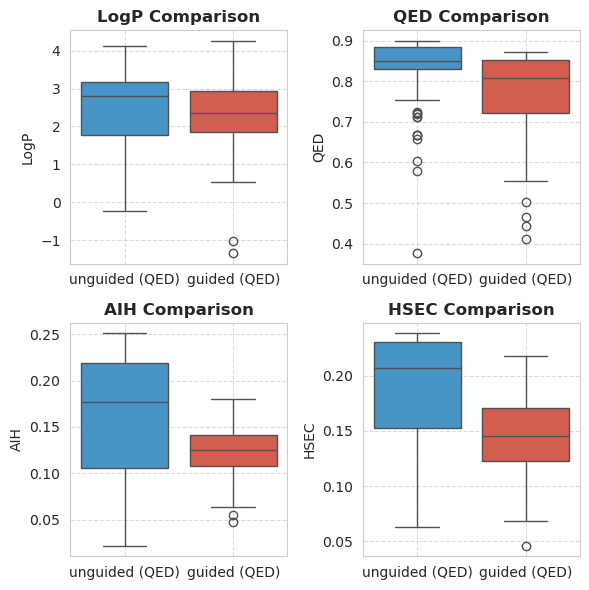

In [29]:
def create_comparison_boxplots(df1, df2, columns=['LogP', 'QED', 'AIH', 'HSEC'], name1 ='Dataset 1', name2 ='Dataset 2' ):
    # Set figure size and style
    plt.figure(figsize=(12, 8))
    sns.set_style("whitegrid")
    
    # Create subplots - one for each column
    fig, axes = plt.subplots(2, 2, figsize=(6, 6))
    axes = axes.flatten()
    
    # Define colors for each dataframe
    colors = ['#3498db', '#e74c3c']
    
    # Create boxplots for each column
    for i, column in enumerate(columns):
        # Create a temporary dataframe for plotting
        temp_df = pd.DataFrame({
            name1: df1[column],
            name2: df2[column]
        })
        
        # Melt the dataframe for seaborn
        melted_df = pd.melt(temp_df, var_name='Dataset', value_name=column)
        
        # Create boxplot
        #sns.boxplot(x='Dataset', y=column, data=melted_df, palette=colors, ax=axes[i])
        # Create boxplot (using hue instead of palette to avoid FutureWarning)
        sns.boxplot(x='Dataset', y=column, hue='Dataset', data=melted_df, palette=colors, legend=False, ax=axes[i])
        
        # Set title and style
        axes[i].set_title(f'{column} Comparison', fontweight='bold')
        axes[i].set_xlabel('')
        axes[i].grid(True, linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()


create_comparison_boxplots(df1, df2, name1="unguided (QED)", name2="guided (QED)")
